# Gradient descent and quadratic penalization

**Continuous optimization — ENT 305**


We study the projection of $(0,1)$ onto the line $x=y$:

$$\min_{(x,y)\in\mathbb R^2} f(x,y)=\frac12\bigl[x^2+(y-1)^2\bigr],\qquad h(x,y)=y-x=0.$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Build the quadratic penalty

For $c>0$, define

$$Q_c(x,y)=f(x,y)+\frac c2\,h(x,y)^2.$$


**Exercise 1.** Compute $\nabla f$, $\nabla h$, $\nabla Q_c$ and $\nabla^2 Q_c$ by hand. Complete the functions below.

In [13]:
def f(x, y):
    return 0.5 * (x*x + (y - 1.0)**2)

def grad_f(x, y):
    return np.array([x, y - 1.0], dtype=float)

def h(x, y):
    return y - x

def grad_h(x, y):
    return np.array([-1.0, 1.0])

def Q(xy, c):
    x, y = np.asarray(xy, dtype=float)
    return f(x, y) + 0.5*c*h(x, y)**2

def grad_Q(xy, c):
    x, y = np.asarray(xy, dtype=float)
    return grad_f(x, y) + c*h(x, y)*grad_h(x, y)

def hessian_Q(c):
    return np.array([[1+c, -c], [-c, 1+c]], dtype=float)


## 2. Gradient descent with an Armijo line search

At each iteration, use the descent direction $d_k=-\nabla Q_c(x_k)$ and choose a step $\alpha_k>0$ satisfying

$$Q_c(x_k+\alpha_k d_k)\le Q_c(x_k)+\sigma\alpha_k\nabla Q_c(x_k)^\top d_k,\qquad 0<\sigma<1.$$

**Exercise 2.** Complete the code and compare the trajectories for $c=1$ and $c=20$.

In [3]:
def armijo_step(x, direction, c, alpha0=1.0, shrink=0.5, sigma=1e-4):
    alpha = alpha0
    slope = np.dot(grad_Q(x, c), direction)
    if slope >= 0:
        raise ValueError('The direction is not a descent direction.')
    for _ in range(60):
        if Q(x + alpha*direction, c) <= Q(x, c) + sigma*alpha*slope:
            return alpha
        alpha *= shrink
    raise RuntimeError('Armijo line search did not find a step.')

def gradient_descent(x0, c, tol=1e-8, max_iter=30000):
    x = np.asarray(x0, dtype=float).copy()
    trajectory = [x.copy()]
    for k in range(max_iter):
        grad = grad_Q(x, c)
        if np.linalg.norm(grad) <= tol:
            return np.asarray(trajectory), True
        direction = -grad
        alpha = armijo_step(x, direction, c)
        x = x + alpha*direction
        trajectory.append(x.copy())
    return np.asarray(trajectory), False

for c in [1.0, 20.0]:
    trajectory, converged = gradient_descent([1.5, -0.5], c)
    print(f'c={c:g}: iterations={len(trajectory)-1}, converged={converged}, '
          f'point={trajectory[-1]}, |h|={abs(h(*trajectory[-1])):.3g}')

c=1: iterations=29, converged=True, point=[0.33333333 0.66666667], |h|=0.333
c=20: iterations=20, converged=True, point=[0.48780488 0.51219512], |h|=0.0244


## 3. Analytical solution of the penalized problem

**Exercise 3.** Show that the descent gradient algorithm converges to 


$$\boxed{(x_c,y_c)=\left(\frac{c}{1+2c},\frac{1+c}{1+2c}\right).}$$


In [14]:
def exact_penalty_solution(c):
    return np.array([c/(1+2*c), (1+c)/(1+2*c)])

for c in [0.5, 1, 5, 20, 100]:
    path, ok = gradient_descent([1.5, -0.5], c, tol=1e-7)
    x_exact = exact_penalty_solution(c)
    print(f'c={c:5g} | GD={path[-1]} | exact={x_exact} | error={np.linalg.norm(path[-1]-x_exact):.2e}')

c=  0.5 | GD=[0.25 0.75] | exact=[0.25 0.75] | error=0.00e+00
c=    1 | GD=[0.33333335 0.66666665] | exact=[0.33333333 0.66666667] | error=2.46e-08
c=    5 | GD=[0.45454546 0.54545454] | exact=[0.45454545 0.54545455] | error=4.47e-09
c=   20 | GD=[0.48780488 0.51219512] | exact=[0.48780488 0.51219512] | error=2.19e-09
c=  100 | GD=[0.49751244 0.50248756] | exact=[0.49751244 0.50248756] | error=4.37e-10


## 4. Effect of the penalty parameter

The solution of the original constrained problem is $\bar z=(1/2,1/2)$. Show that

$$|h(x_c,y_c)|=\frac1{1+2c},\qquad \| (x_c,y_c)-\bar z\|=\frac1{\sqrt2(1+2c)}.$$

**Exercise 4.** Plot these two errors as functions of $c$. What happens as $c\to\infty$? Does any finite $c$ enforce the constraint exactly?


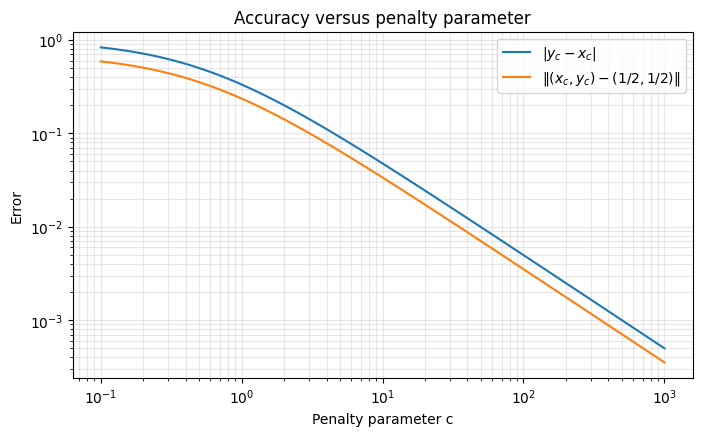

In [5]:
c_values = np.logspace(-1, 3, 100)
feasibility = np.array([abs(h(*exact_penalty_solution(c))) for c in c_values])
distance = np.array([np.linalg.norm(exact_penalty_solution(c)-[0.5,0.5]) for c in c_values])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(c_values, feasibility, label=r'$|y_c-x_c|$')
ax.loglog(c_values, distance, label=r'$\|(x_c,y_c)-(1/2,1/2)\|$')
ax.set(xlabel='Penalty parameter c', ylabel='Error', title='Accuracy versus penalty parameter')
ax.grid(True, which='both', alpha=0.3)
ax.legend(); plt.show()

## 5. Visualize the iterates

**Exercise 5.** Superimpose the trajectories of gradient descent on level curves of $Q_c$, and draw the line $x=y$. 


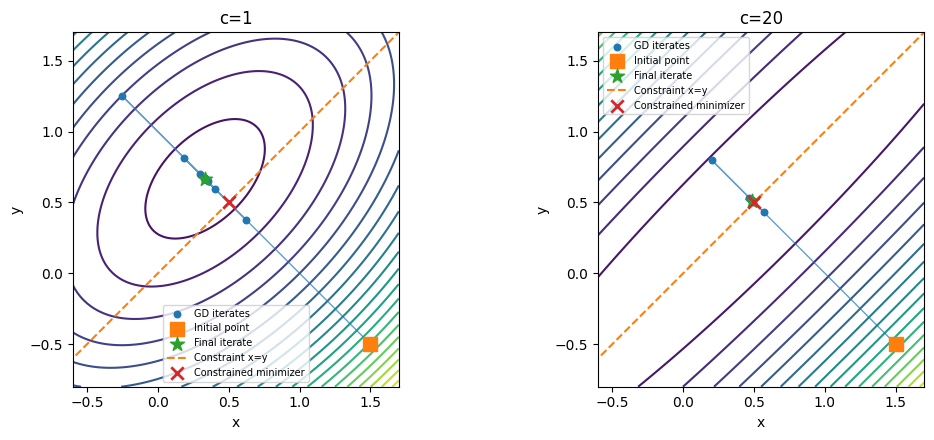

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

xx, yy = np.meshgrid(
    np.linspace(-0.6, 1.7, 150),
    np.linspace(-0.8, 1.7, 150)
)

for ax, c in zip(axes, [1.0, 20.0]):

    values = 0.5*(xx**2 + (yy-1)**2) + 0.5*c*(yy-xx)**2
    ax.contour(xx, yy, values, levels=20)

    path, _ = gradient_descent([1.5, -0.5], c)

    # Trajectory
    ax.plot(path[:, 0], path[:, 1], '-',
            linewidth=1, alpha=0.7)

    # All iterations
    ax.scatter(path[:, 0], path[:, 1],
               s=22, zorder=4, label='GD iterates')

    # Iteration numbers (first 10)


    # Initial and final points
    ax.scatter(*path[0], s=90, marker='s',
               zorder=5, label='Initial point')
    ax.scatter(*path[-1], s=110, marker='*',
               zorder=6, label='Final iterate')

    # Constraint and constrained minimizer
    ax.plot([-0.8, 1.7], [-0.8, 1.7], '--',
            label='Constraint x=y')
    ax.scatter(0.5, 0.5, s=80, marker='x',
               linewidths=2, zorder=7,
               label='Constrained minimizer')

    ax.set(
        xlim=(-0.6, 1.7),
        ylim=(-0.8, 1.7),
        xlabel='x',
        ylabel='y',
        title=f'c={c:g}'
    )
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


## 6. Conditioning: the limitation of the method

The Hessian of $Q_c$ is

$$\nabla^2 Q_c=\begin{pmatrix}1+c&-c\\-c&1+c\end{pmatrix}.$$

**Exercise 6.** Show that its eigenvalues are $1$ and $1+2c$. Deduce that $Q_c$ is strongly convex, but that

$$\kappa_2(\nabla^2 Q_c)=1+2c\longrightarrow+\infty.$$

Measure the number of gradient-descent iterations needed as $c$ increases. 

In [9]:
test_c = np.array([0.5, 1, 2, 5, 10, 20, 50, 100], dtype=float)
rows = []
for c in test_c:
    path, ok = gradient_descent([1.5, -0.5], c, tol=1e-6, max_iter=20000)
    rows.append((c, np.linalg.cond(hessian_Q(c)), len(path)-1, abs(h(*path[-1])), ok))
print('     c   condition number    GD iterations      |h|      converged')
for c, cond, iters, violation, ok in rows:
    print(f'{c:7.1f} {cond:17.1f} {iters:16d} {violation:12.5g}   {ok}')

     c   condition number    GD iterations      |h|      converged
    0.5               2.0                1          0.5   True
    1.0               3.0               23      0.33333   True
    2.0               5.0               12          0.2   True
    5.0              11.0               17     0.090909   True
   10.0              21.0               15     0.047619   True
   20.0              41.0               15      0.02439   True
   50.0             101.0               35     0.009901   True
  100.0             201.0               35    0.0049751   True


## 7. Quadratic-penalty algorithm 

For a prescribed feasibility tolerance $\varepsilon_{\rm feas}$, increase $c$ progressively, using the previous solution as the initial point for the next unconstrained minimization.

**Exercise 7.** Complete the code 


In [16]:
def penalty_method(x0, c0=0.5, growth=5.0, feasibility_tol=1e-3, max_outer=12):
    x = np.asarray(x0, dtype=float)
    c = c0
    history = []
    for outer in range(max_outer):
        path, converged = gradient_descent(x, c, tol=1e-7, max_iter=30000)
        x = path[-1]
        violation = abs(h(*x))
        history.append((c, x.copy(), violation, len(path)-1, converged))
        if violation <= feasibility_tol:
            break
        c *= growth
    return x, history

x_result, history = penalty_method([1.5, -0.5])
for c, x, violation, iterations, converged in history:
    print(f'c={c:8.2f} x={x} |h|={violation:.3e} GD iterations={iterations} converged={converged}')
print('Final constrained-solution error:', np.linalg.norm(x_result-[0.5,0.5]))

c=    0.50 x=[0.25 0.75] |h|=5.000e-01 GD iterations=1 converged=True
c=    2.50 x=[0.41666666 0.58333334] |h|=1.667e-01 GD iterations=24 converged=True
c=   12.50 x=[0.48076923 0.51923077] |h|=3.846e-02 GD iterations=37 converged=True
c=   62.50 x=[0.49603175 0.50396825] |h|=7.937e-03 GD iterations=530 converged=True
c=  312.50 x=[0.49920128 0.50079872] |h|=1.597e-03 GD iterations=13 converged=True
c= 1562.50 x=[0.49984005 0.50015995] |h|=3.199e-04 GD iterations=31 converged=True
Final constrained-solution error: 0.0002262017995671506
